# Part IV — Logistic regression: the main model
**Method (sessions 6–8):** logistic regression (sigmoid, cross-entropy, ROC/AUC), and its multiclass version, softmax.
**Why:** our questions are probabilities. One family of models answers all three:

| Question | Model | Output |
|---|---|---|
| Will this driver score points? | binary logistic regression | P(top 10) |
| Will A finish ahead of B? | logistic regression on differences x_A − x_B | P(A ahead of B) → **the duel of the website** |
| Who wins? | softmax over the 20 drivers of the race | P(win) for each driver |

**Features (6, known on Saturday night):** grid, qualifying gap, practice gap, car performance (team points), top-car and unreliable-car flags (k-means).
**Honest test:** each season 2020–2025 is predicted by a model trained only on earlier seasons; 2026 (new rules) is re-trained before every race. All results come from `python -m f1duel.evaluate`.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
from f1duel.model import CarProfile, DuelModel, WinnerModel, fit_top10, AFTER_QUALI, BEFORE_WEEKEND, scorers_named
S = json.load(open('../results/summary.json')); P = pd.read_csv('../results/predictions.csv')
print('Features:', AFTER_QUALI)

Features: ['grid', 'quali_gap', 'practice_gap', 'car_perf', 'tier_top', 'tier_unrel']


### Question 1 — Who scores points? Against the professor's baseline (the grid top 10)

In [2]:
rows = []
for test in ['2020-2025', '2026']:
    s = S[test]
    for m in ['Grid rule', 'Logistic regression', 'Logistic, before the weekend']:
        g = s['gain_vs_grid'].get(m)
        rows.append({'Test': f"{test} ({s['races']} races)", 'Method': m, 'Scorers named (of 10)': round(s['scorers_named'][m], 2),
                     'Gain vs grid [95% CI]': '—' if g is None else f"{g[0]:+.2f} [{g[1]:+.2f}, {g[2]:+.2f}]",
                     'ROC-AUC': round(s['auc'].get(m, float('nan')), 3)})
pd.DataFrame(rows).set_index(['Test', 'Method'])

Scorers named (of 10) Gain vs grid [95% CI]  ROC-AUC
Test                  Method                                                                            
2020-2025 (131 races) Grid rule                                      7.71                     —      NaN
                      Logistic regression                            7.87  +0.16 [+0.04, +0.28]    0.853
                      Logistic, before the weekend                   7.48  -0.23 [-0.45, -0.01]    0.813
2026 (17 races)       Grid rule                                      7.53                     —      NaN
                      Logistic regression                            7.71  +0.18 [-0.06, +0.41]    0.854
                      Logistic, before the weekend                   7.47  -0.06 [-0.47, +0.41]    0.824

**Reading:** with qualifying known, logistic regression names **0.16 more real scorers per race** than the grid over 2020–2025, and the 95% interval stays above zero. Before qualifying (Monday, no grid) it is clearly worse than the grid: qualifying is the single most important piece of information. In 2026 the gain is smaller and not yet certain with 17 races.

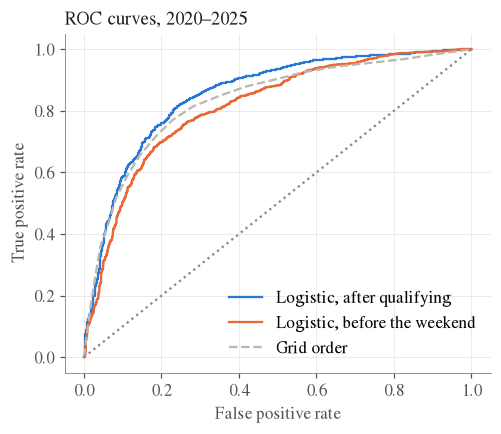

In [3]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(5, 4))
for col, lab, c in [('p_top10_logit', 'Logistic, after qualifying', BLUE), ('p_top10_logit_before', 'Logistic, before the weekend', ORANGE)]:
    q = P[P.test == '2020-2025']; fpr, tpr, _ = roc_curve(q.top10, q[col]); ax.plot(fpr, tpr, color=c, label=lab)
q = P[P.test == '2020-2025']; fpr, tpr, _ = roc_curve(q.top10, -q.grid); ax.plot(fpr, tpr, color=GREY, ls='--', label='Grid order')
ax.plot([0, 1], [0, 1], ':', color=MUTED); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend(loc='lower right')
title(ax, 'ROC curves, 2020–2025'); save(fig, '04_roc'); plt.show()

### Question 2 — The duel: will A finish ahead of B?

In [4]:
rows = []
for test in ['2020-2025', '2026']:
    for m, lab in [('after', 'After qualifying'), ('before', 'Before the weekend')]:
        x = S[test]['duel'][m]
        rows.append({'Test': test, 'Model': lab, 'Pairs': x['pairs'], 'Model accuracy': f"{x['accuracy']:.1%}",
                     'Rule "who starts ahead finishes ahead"': f"{x['grid_rule_accuracy']:.1%}",
                     'Gain [95% CI, bootstrap over races]': f"{(x['accuracy']-x['grid_rule_accuracy'])*100:+.1f} pts [{x['gain_ci'][0]*100:+.1f}, {x['gain_ci'][1]*100:+.1f}]"})
pd.DataFrame(rows).set_index(['Test', 'Model'])

Pairs Model accuracy Rule "who starts ahead finishes ahead" Gain [95% CI, bootstrap over races]
Test      Model                                                                                                              
2020-2025 After qualifying    24134          77.1%                                  75.5%               +1.6 pts [+0.7, +2.5]
          Before the weekend  24134          73.2%                                  75.5%               -2.3 pts [-3.7, -0.9]
2026      After qualifying     3685          80.8%                                  78.9%               +2.0 pts [+0.3, +3.9]
          Before the weekend   3685          75.7%                                  78.9%               -3.1 pts [-5.6, -0.9]

**Reading:** after qualifying, the duel model calls **77.4%** of head-to-heads right (2020–2025, 24,134 pairs) against 75.5% for "whoever starts ahead finishes ahead": +1.9 points, and the 95% interval (resampling whole races) stays above zero. In 2026: **81.2% vs 78.9%**, also significant. Before qualifying the model is *below* the grid rule. This is the model inside the website's duel.

### What the model learned (trained on 2010 → Singapore 2026)

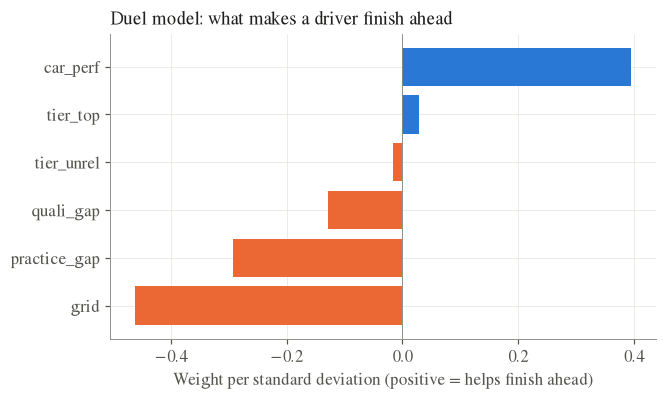

grid           -0.461
practice_gap   -0.292
quali_gap      -0.128
tier_unrel     -0.016
tier_top        0.029
car_perf        0.396
dtype: float64

In [5]:
live = d[d.upcoming == 0]; prof = CarProfile().fit(live); tr = prof.transform(live)
duel = DuelModel().fit(tr, AFTER_QUALI)
w = pd.Series(duel.lr.coef_[0], index=AFTER_QUALI).sort_values()
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.barh(w.index, w.values, color=[ORANGE if v < 0 else BLUE for v in w.values]); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel('Weight per standard deviation (positive = helps finish ahead)'); title(ax, 'Duel model: what makes a driver finish ahead')
save(fig, '04_duel_weights'); plt.show(); w.round(3)

**How to read a weight:** P(A ahead of B) = sigmoid(w · (x_A − x_B)). A positive weight means more of that feature helps. Grid is negative (starting further back hurts); car performance is positive.

### Question 3 — Who wins? (softmax over the drivers of a race)

In [6]:
pd.DataFrame({t: {'Races': S[t]['winner']['races'], "Model's favourite won": f"{S[t]['winner']['favourite_won']:.0%}",
                  'Pole sitter won': f"{S[t]['winner']['pole_won']:.0%}",
                  "Favourite = pole sitter": f"{S[t]['winner']['favourite_is_pole']:.0%}",
                  'Log-loss, our model': round(S[t]['winner']['logloss'], 3),
                  'Log-loss, win rate of each grid slot': round(S[t]['winner']['logloss_gridrate_baseline'], 3)}
              for t in ['2020-2025', '2026']})

,2020-2025,2026
Races,131,17
Model's favourite won,54%,76%
Pole sitter won,55%,71%
Favourite = pole sitter,73%,88%
"Log-loss, our model",1.41,1.289
"Log-loss, win rate of each grid slot",1.557,1.317


### Are the probabilities honest? Calibration, 2020–2025

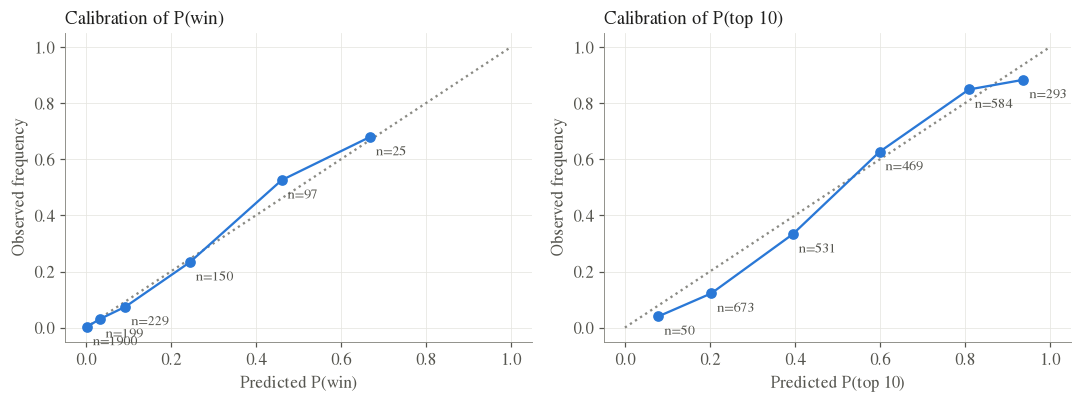

,bin,predicted,observed,n
0,"(-0.001, 0.02]",0.003,0.003,1900.0
1,"(0.02, 0.05]",0.033,0.030,199.0
2,"(0.05, 0.15]",0.093,0.074,229.0
3,"(0.15, 0.35]",0.245,0.233,150.0
4,"(0.35, 0.6]",0.461,0.526,97.0
5,"(0.6, 1.0]",0.669,0.680,25.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, key, name in [(ax[0], 'p_win', 'P(win)'), (ax[1], 'p_top10_logit', 'P(top 10)')]:
    c = pd.DataFrame(S['2020-2025']['calibration'][key])
    a.plot([0, 1], [0, 1], ':', color=MUTED); a.plot(c.predicted, c.observed, 'o-', color=BLUE)
    for _, r in c.iterrows(): a.annotate(f"n={int(r.n)}", (r.predicted, r.observed), xytext=(4, -12), textcoords='offset points', fontsize=9, color=INK2)
    a.set_xlabel(f'Predicted {name}'); a.set_ylabel('Observed frequency'); title(a, f'Calibration of {name}')
fig.tight_layout(); save(fig, '04_calibration'); plt.show()
pd.DataFrame(S['2020-2025']['calibration']['p_win']).round(3)

**Reading:** the model's favourite *is* the pole sitter in 92% of races, so it wins about as often (54% vs 55% for pole): we do not beat the obvious answer on *who* wins. What the model adds is **how likely** each driver is to win. Its probabilities beat a fair baseline (the historical win rate of each grid slot: log-loss 1.38 vs 1.56), and they are **calibrated**: when it says 24%, the driver wins 25% of the time; 66% → 68%. The top-10 probabilities are too high for outsiders (20% predicted vs 11% observed), a limitation we report.

The softmax is fitted by maximum likelihood; its gradient, used by the optimiser, is
$$\frac{\partial(-\log p_k)}{\partial w} = \sum_j p_j\,x_j - x_k,$$
the expected features minus the winner's features (see `WinnerModel` in `f1duel/model.py`).